# w12b — Regression Inference in Python
**ENGR 1451/2451 · Exploratory Data Science · Fall 2026**

Fit a line with `smf.ols`, check the residuals as in **w06b**, and compare confidence and prediction intervals. The slides develop the formulas; this notebook focuses on the Python.

**Setup:** Keep `data/twins.csv` in a `data/` folder beside this notebook. Run the cells from top to bottom. The final exercise contains runnable starter code; complete the commented tasks in class.

*The 27 twin pairs are the same observations plotted in the supplied w12b slides. Original source: [OpenIntro twin data](https://openintrostat.github.io/openintro/reference/twins.html). These historical data illustrate regression calculations, not a causal genetic mechanism.*

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

## 1. Read the data and fit the line

`biological` is the predictor $x$; `foster` is the response $y$. Each row is one twin pair.

The formula `foster ~ biological` fits $\hat y=b_0+b_1x$, including an intercept.

In [4]:
twins = pd.read_csv("data/twins.csv")
display(twins.head())

,biological,foster
0,82,82
1,90,80
2,91,88
3,115,108
4,115,116


In [5]:

model = smf.ols("foster ~ biological", data=twins).fit()
print(model.summary())
print(f"R² = {model.rsquared:.3f}")


                            OLS Regression Results                            
Dep. Variable:                 foster   R-squared:                       0.778
Model:                            OLS   Adj. R-squared:                  0.769
Method:                 Least Squares   F-statistic:                     87.56
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.20e-09
Time:                        07:46:37   Log-Likelihood:                -92.488
No. Observations:                  27   AIC:                             189.0
Df Residuals:                      25   BIC:                             191.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.2076      9.300      0.990      0.3

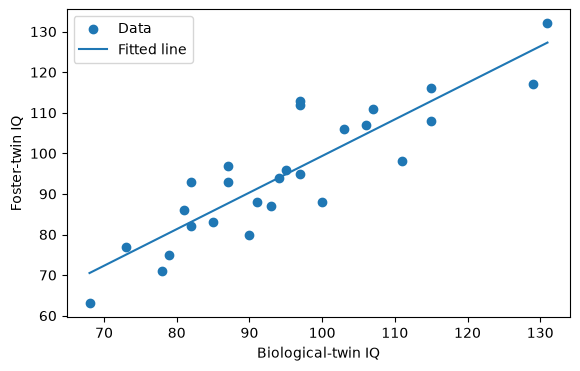

In [6]:

plt.figure(figsize=(6.5, 4))
plt.scatter(twins["biological"], twins["foster"], label="Data")
x = [twins["biological"].min(), twins["biological"].max()]
plt.plot(x, model.predict({"biological": x}), label="Fitted line")
plt.xlabel("Biological-twin IQ")
plt.ylabel("Foster-twin IQ")
plt.legend()
plt.show()

## 2. Check the residuals before interpreting inference

A residual is **observed minus fitted**: $e_i=y_i-\hat y_i$. Use `model.fittedvalues` and `model.resid` directly.

As in w06b, look for **curvature**, **changing vertical spread**, or **isolated observations**. A reasonable plot has residuals scattered around zero with no clear pattern. A large $R^2$ does not replace these checks.

,biological,foster,fitted,residual
0,82,82,83.125351,-1.125351
1,90,80,90.336839,-10.336839
2,91,88,91.238275,-3.238275
3,115,108,112.872739,-4.872739
4,115,116,112.872739,3.127261


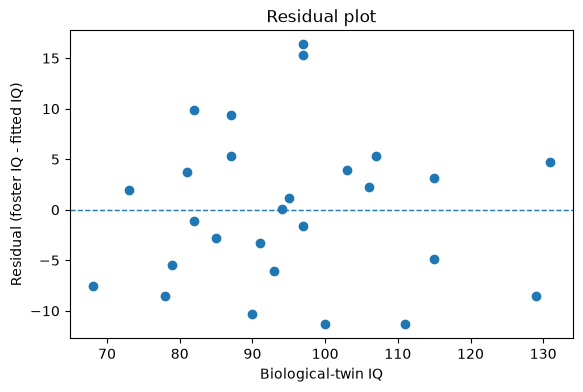

In [7]:
display(twins.assign(fitted=model.fittedvalues, residual=model.resid).head())

plt.figure(figsize=(6.5, 4))
plt.scatter(twins["biological"], model.resid)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Biological-twin IQ")
plt.ylabel("Residual (foster IQ - fitted IQ)")
plt.title("Residual plot")
plt.show()

### Two quick shape checks

The **histogram** shows asymmetry and unusual residuals. The **normal probability plot** compares ordered residuals with normal-reference quantiles; approximately straight points support a roughly normal error shape.

**Discuss:** Is there pronounced skew or a strong departure from the reference line? With only 27 pairs, these are visual checks, not proof of normality. Normality concerns the errors around the line, not the raw IQ values.

Independence and representativeness require information about the study design. Here, independence is **between twin pairs**.

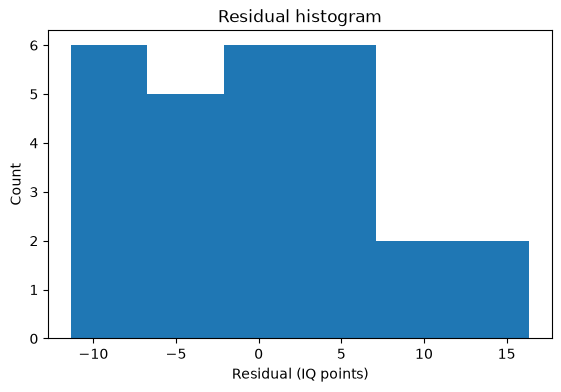

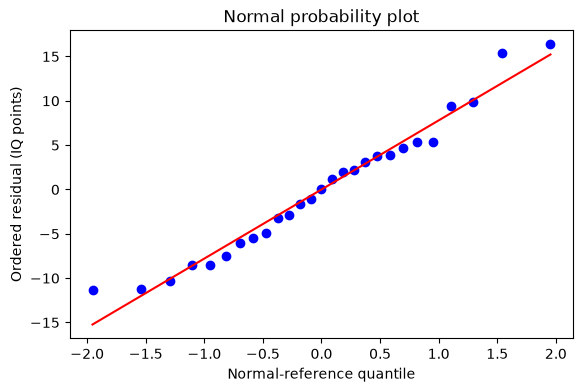

In [8]:
plt.figure(figsize=(6.5, 4))
plt.hist(model.resid, bins="auto")
plt.xlabel("Residual (IQ points)")
plt.ylabel("Count")
plt.title("Residual histogram")
plt.show()

plt.figure(figsize=(6.5, 4))
stats.probplot(model.resid, dist="norm", plot=plt)
plt.xlabel("Normal-reference quantile")
plt.ylabel("Ordered residual (IQ points)")
plt.title("Normal probability plot")
plt.show()

### One-observation sensitivity check

Refit without the observation with the largest absolute residual and compare coefficients. **Does the slope change much?**

This is a sensitivity check, **not a reason to delete an observation**. A large residual is not necessarily influential; this check does not examine every potentially influential point. Keep the original `model` for the remaining analysis.

In [9]:
pair_to_check = model.resid.abs().idxmax()
display(twins.loc[[pair_to_check]])

model_without = smf.ols(
    "foster ~ biological", data=twins.drop(index=pair_to_check)
).fit()

display(pd.DataFrame({
    "All pairs": model.params,
    "Without selected pair": model_without.params,
}).round(4))

,biological,foster
23,97,113


,All pairs,Without selected pair
Intercept,9.2076,9.0068
biological,0.9014,0.8969


## 3. Test the slope and find its confidence interval

$$H_0:\beta_1=0,\qquad H_A:\beta_1\ne0.$$

Read the **biological** row of the coefficient table. Its P-value is for the two-sided slope test, with $df=n-2$. A 95% slope confidence interval excluding zero agrees with rejection at $\alpha=0.05$.

**Interpret:** What does one additional biological-twin IQ point correspond to on the fitted line? The intercept refers to $x=0$, outside the observed range. Neither a small P-value nor $R^2$ establishes causation.

In [10]:
print(f"Slope = {model.params['biological']:.4f}")
print(f"Slope P-value = {model.pvalues['biological']:.3g}")
print("95% confidence intervals for the coefficients:")
display(model.conf_int().rename(columns={0: "Lower", 1: "Upper"}))

Slope = 0.9014
Slope P-value = 1.2e-09
95% confidence intervals for the coefficients:


,Lower,Upper
Intercept,-9.945896,28.361094
biological,0.703035,1.099837


## 4. Confidence interval or prediction interval?

At a biological-twin IQ of **100**, `statsmodels` calculates both intervals automatically.

| Output | Meaning |
|---|---|
| `mean` | Fitted response at the chosen $x$ |
| `mean_ci_lower`, `mean_ci_upper` | 95% confidence interval for the **population mean response** |
| `obs_ci_lower`, `obs_ci_upper` | 95% prediction interval for **one new response** |

The prediction interval is wider because it includes individual scatter as well as uncertainty in the estimated mean. Neither is the confidence interval for the **slope**.

In [11]:
at_100 = pd.DataFrame({"biological": [100]})
intervals_100 = model.get_prediction(at_100).summary_frame(alpha=0.05)
display(intervals_100.round(2))

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,99.35,1.55,96.15,102.55,83.11,115.59


### Plot both intervals

`fill_between()` shades the intervals across the observed predictor range. These are **pointwise 95% intervals**, not simultaneous coverage of the entire line.

**Discuss:** Which interval describes a new individual? Why do the intervals widen farther from the average observed $x$?

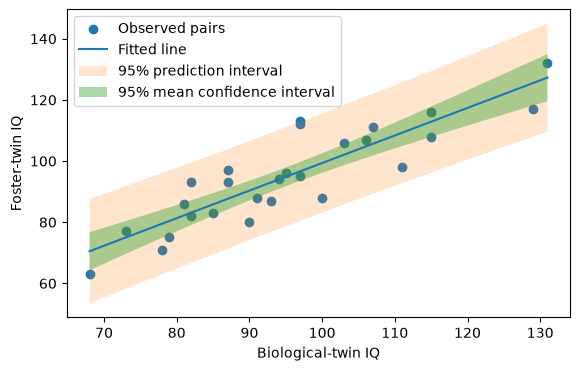

In [12]:
x_grid = np.linspace(twins["biological"].min(), twins["biological"].max(), 100)
new_data = pd.DataFrame({"biological": x_grid})
pred = model.get_prediction(new_data).summary_frame(alpha=0.05)

plt.figure(figsize=(6.5, 4))
plt.scatter(twins["biological"], twins["foster"], label="Observed pairs")
plt.plot(x_grid, pred["mean"], label="Fitted line")
plt.fill_between(x_grid, pred["obs_ci_lower"], pred["obs_ci_upper"],
                 alpha=0.2, label="95% prediction interval")
plt.fill_between(x_grid, pred["mean_ci_lower"], pred["mean_ci_upper"],
                 alpha=0.4, label="95% mean confidence interval")
plt.xlabel("Biological-twin IQ")
plt.ylabel("Foster-twin IQ")
plt.legend()
plt.show()

## 5. Summary and Python function reference

**Check the model before trusting its inference.** Residual plots assess shape and spread; study design addresses independence and representativeness. A slope CI, a mean-response CI, and a prediction interval answer different questions.

| Function or attribute | Purpose |
|---|---|
| `smf.ols("y ~ x", data=df).fit()` | Fit a line with an intercept. |
| `model.summary()` | Display regression output. |
| `model.params`, `model.pvalues` | Get coefficients and their P-values. |
| `model.conf_int()` | Get coefficient confidence intervals. |
| `model.rsquared` | Get $R^2$. |
| `model.fittedvalues`, `model.resid` | Get fitted responses and residuals. |
| `model.predict(new_data)` | Predict responses at named predictor values. |
| `plt.scatter(x, model.resid)` | Check curvature, spread, and unusual residuals. |
| `plt.hist(model.resid)` | Inspect the residual distribution. |
| `stats.probplot(model.resid, plot=plt)` | Make a normal probability plot. |
| `model.get_prediction(new_data).summary_frame()` | Get fitted means, mean CIs, and prediction intervals. |
| `plt.fill_between(x, lower, upper)` | Shade an interval. |

## 6. Your turn — sensor calibration

The data below give measured force (N) versus sensor voltage (V).

1. Fit `force ~ voltage` with `smf.ols`. Report the slope, $R^2$, and the P-value for $H_0:\beta_1=0$.
2. Plot residuals versus voltage. Do you see curvature, changing spread, or an unusual observation? What does the small sample prevent you from concluding confidently?
3. At **2.5 V**, report the fitted force, 95% **mean-response CI**, and 95% **prediction interval**. Explain which interval is wider.

Use the patterns above; no manual standard-error calculations are needed.

In [13]:
sensor = pd.DataFrame({
    "voltage": [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0],
    "force":   [4.1, 7.2, 9.4, 12.8, 15.0, 18.5, 20.2, 23.9],
})

# 1. Fit sensor_model and report its slope, R², and slope P-value.

# 2. Plot sensor_model.resid versus sensor["voltage"].

# 3. Predict at 2.5 V and compare the two intervals.